# Programming assignment 1 - Graphics

In this assignment we want you to plot a room, which you can move around in. Here is a (colourful) room:

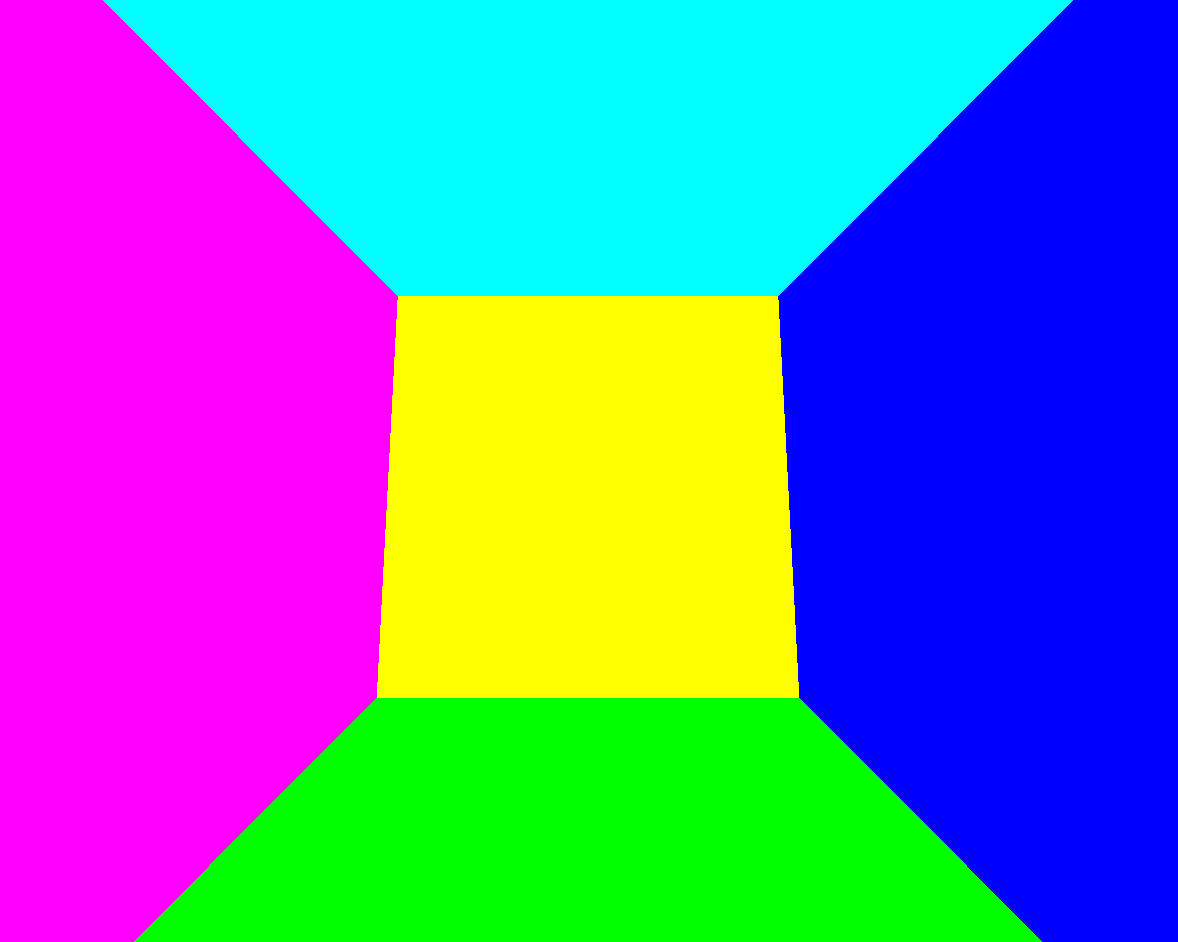

The room is rotated...

![rotated view](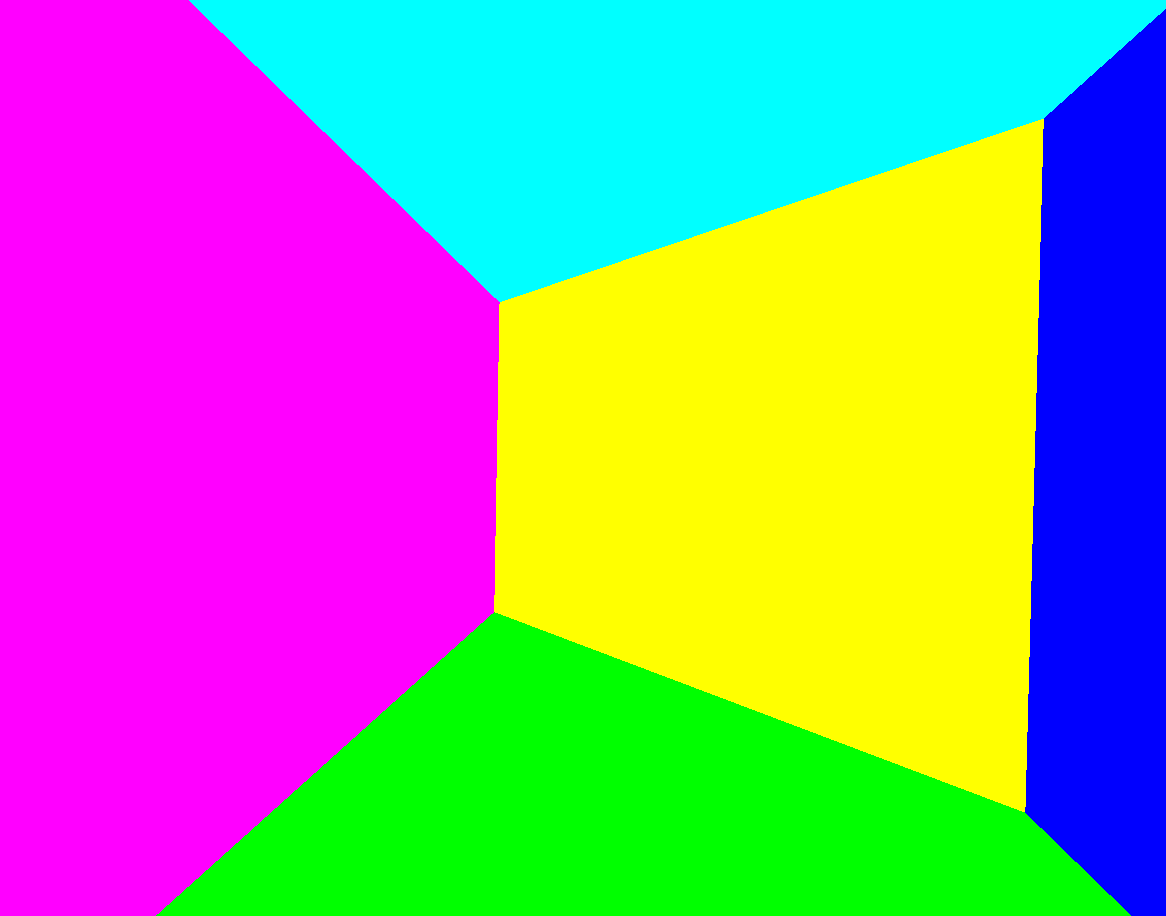
)

The camera moves down...

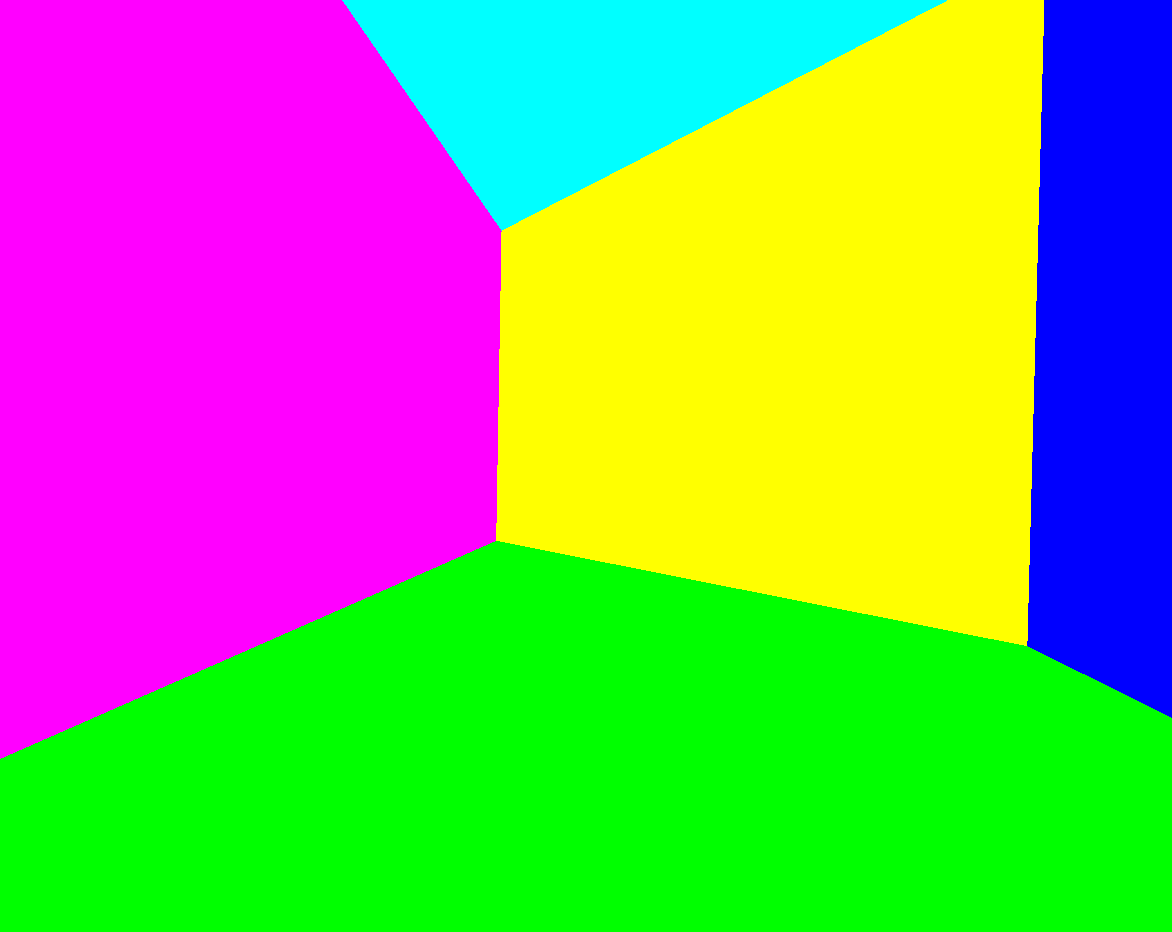

## The assignment

The submission will simply be the code for your room. It must:

1. Implement a class for the 3d model.
2. Draw a 2d realization to the screen using perspective, i.e. the 3d-2d strategy from the lecture 2025-02-14 "camera and projective geometry".
3. Move the camera on a keystroke (or mouse input), and redraw the screen.
4. Rotate the camera on a keystroke (or mouse input) using quaternions, and redraw.
5. Include a sample 3d model (you can use mine, or create your own).
6. Be easy to run, from e.g. a python IDE, and respond to keystrokes.

You are required to use python to implement the model. It is encouraged to use pyglet, but you may use another tool for drawing. However, you gain __no marks__ for implementing projections, rotations and translations using built-in codes from python packages such as pyglet. You must code these yourself using numpy to obtain credit.

## 1. 3D Model [20 points]

The basic ingredients for your code should be a 3d model of triangular surfaces of a given colour. You will need to specify:

1. __Nodes__ - an array containing the x-, y- and z- coordinates of all the vertices (nodes) of the triangles.
2. __Elements__ - an array where row $i$ is a list identifying where to find the three nodes of element (triangle) $i$ in the array of nodes, i.e. Elements[i] could be [0 1 2] if its nodes have coordinates Nodes[0], Nodes[1], and Nodes[2].
3. __Colors__ - a similar array where row $i$ contains the RGB-colors of element $i$. This could be combined with the array of elements, but I prefer to divide it up.

_Aside: the terminology Node/Element is borrowed from finite element methods, where the elements need not be (but often are) triangles. Here 'node' and 'vertex' are interchangeable, and all 'elements' are triangles._ 

If you are still confused, there is a short demonstration in section 5 where the sample 3d model is presented. 

It is normal (and implicit in the text above) that the row number is the node/element number, so that Nodes[0] is a 3d row vector of coordinates. Overall this probably makes things easier, but mostly it is simply the standard.

Note that this conflicts with the suggestion in assignment 4 of having a quaternion rotate a list of _column_ vectors. So be careful! My code ending up using np.transpose all over the place, although I could have avoided had I been a bit smarter...

Your code should build on the following class:

In [ ]:
import pyglet
class Model_3d:
    def __init__(self, nodes, elements, colors):
        self.nodes = nodes
        self.elements = elements
        self.colors = colors
        # *****************************************************
        # How you implement the 2D drawing is up to you (although see the comments
        # on not gaining credit for inbuilt routines for rotation etc)
        # You may choose to follow my strategy:
        # *****************************************************
        # I chose to implement the 3D to 2D conversion as below
        # I assign one pyglet batch to the 3d model
        self.batch = pyglet.graphics.Batch()
        # the 2D elements will be Pyglet triangles, i.e. pyglet.shapes.Triangle()
        # I store them in a dictionary indexed by the element positions
        # This is because I only want to generate 2d triangles for 'visible' elements
        self.triangles = {}
    # ***************************************************
    # Your class should include all the following:
    def add_nodes(self, nodes): # 5 points
        # Add a node to the model
        return 0
    def delete_node(self, j): # 5 points
        # Remove a node from the model
        return 0
    def add_element(self, element, color, back=True): # 5 points
        # Add an element to the model
        # remember that each element has an associated color...
        return 0
    def delete_element(self, i): # 5 points
        # Remove an element from the model
        return 0
    def rotate(self, quaternion): # up to 25 points, including the quaternion code
        # Rotate the nodes with a quaternion
        return 0
    def translate(self, vector): # 10 points
        # Translate the nodes with a vector
        return 0
    def draw_element(self, element_i, focal_length, X, Y): # 10 points
        # Draw element i
        # This adds a pyglet triangle to the dictionary self.triangles
        # X and Y are the width and height of the screen
        return 0
    def draw(self, focal_length, window_width, window_height): # up to 25 points
        # Draw the model to the screen
        return 0
    # *************************************************************************************
    # The tricky bit will be how to handle elements which are partially visible (see below)
    # My code used two routines, one to divide an element
    # (In fact I used two different divide element routines according to the number of invisible vertices)
    def divide_element(self, element_i):
        return 0
    # And another to remove previous subdivisions when the camera is moved
    def clean_triangles(self):
        return 0
    # You may find a better way of organizing this!

The 20 points are for general handling of the class. The specifics for drawing, translating and rotation will be marked under the next points.

## 2. Draw elements [35 points]

In perspective, a 3d triangle with vertices with coordinates $X,Y,Z$ becomes a 2d coordinate with coordiantes

$$
fX/Z, fY/Z,
$$

where $f$ is the focal length (provided $Z>0$). You code should draw these, as hinted in the class above. [10 points]

### Invisible and partially visible elements [25 points]

The tricky thing will be how to handle invisible or partially visible elements. Two things can cause invisibility:

1. A node is behind you (i.e. $Z \leq 0$)
2. Your line of sight is blocked

We will ignore 2 for now, because we will treat it together with lighting later in the course. But for a best possible grade you will need to handle 1.

Of course, if all the nodes of an element are behind you, don't plot the element! [5 points]

If some nodes are behind you and some in front of you, you can:
- Not plot the element [5 points]. The easy way out. Sufficient to pass, but not for full marks
- Plot the visible part of the element [20 points]. Needed for full marks!

My solution was to split the element into 3, some visible, some invisible. This solution is natural for a numerical mathematician; we always want to divide elements into smaller ones dynamically, although there are other ways. I also implemented a routine which bins the subdivisions when you move the camera, otherwise the number of elements can grow dramatically.

## 3. Translation [10 points]

Moving about (in space) should not be the most difficult bit...

You could implement a collision detection routine to stop you walking through walls, but we will not require this (even for full marks).

## 4. Quaternions [25 points]

We want you to implement rotation using the quaternion class you wrote in weekly assignment 4. This is important! Solutions that use rotations from, e.g. pyglet, will not gain credit.

In [ ]:
import quaternions
import numpy as np

or

In [ ]:
class Quaternion:
    def __init__(self, scalar, vec):
        # My code has a different initalization routine than that of assignment 4
        # This is because I want to allow for a list of quaternions
        # This will make rotate_vector parellalize nicer (see below)
        # But you will have to check that __add__, __mul__ etc vectorize nicely
        # It is of course acceptable to reuse your code from Assignment 4 as is
        # ********************************
        # scalar 1xn
        s = np.array(scalar)
        # vector 3xn
        v = np.array(vec)
        if (np.size(v, axis=0) != 3) or s.ndim != 1:
            raise ValueError('Cannot initialize quaternion with fewer or more than four parameters')
        if np.size(v, axis=1) != s.size:
            raise ValueError('Number of scalars and vectors not equal')
        self.scalar = s
        self.vec = v
    def __repr__(self):
        return 0
    def __add__(self, other):
        return 0
    def __mul__(self, other):
        return 0
    def __abs__(self):
        return 0
    def inverse(self):
        return 0
    @classmethod
    def from_rotation(cls, vector, angle):
        return 0
    def rotate_vector(self, vector):
        n = np.size(vector,axis=1)
        versor = Quaternion(np.zeros(n),vector)
        # ***********************************************
        versor1 = self * versor * self.inverse()
        return versor1.vec    

## 5. The model (e.g. THE ROOM) [0 points]

I simply built my "mesh" (i.e. list of nodes and elements) by hand, in addition to the colors. For more advanced pictures, it is possible to generate meshes using programs such as https://gmsh.info

It is 2025 and most likely AI will generate meshes for you too. Feel free to explore this at leisure. We will not require anything advanced at this stage, but the course will be more fun in later exercises if you have learnt how to make more interesting meshes.

No points here as you can just use mine (THE ROOM).

In [1]:
# THE ROOM

import numpy as np

Nodes = 100*np.transpose(np.array([[-1,1,-1,1,-1,1,-1,1],[-1,-1,1,1,-1,-1,1,1],[-1,-1,-1,-1,1,1,1,1]]))

Elements = np.array([[0,1,2],[1,2,3],[0,1,5],[0,4,5],[1,5,7],[1,3,7],[0,2,6],[0,4,6],[4,5,7],[4,6,7],
              [2,3,7],[2,6,7]])

R = [255,0,0]
G = [0,255,0]
B = [0,0,255]
M = [255,0,255]
Y = [255,255,0]
C = [0,255,255]

Colors = np.array([R,R,G,G,B,B,M,M,Y,Y,C,C],dtype=np.uint32)

For example, Node 0 is at $(-100,-100,-100)$:

In [3]:
Nodes[0]

array([-100, -100, -100])

Element (triangle) 0 has nodes 0, 1, 2 as vertices:

In [4]:
Elements[0]

array([0, 1, 2])

The coordinates of all the nodes of element 0:

In [2]:
Nodes[Elements[0]]

array([[-100, -100, -100],
       [ 100, -100, -100],
       [-100,  100, -100]])

## 6. The application [10 points]

In [ ]:
# # Build the model
# Z = model2.Model_3d(A,E,Colors)

# # Rotations about different axes
# # You can choose different rotation increments if you want
# qx = quaternions.Quaternion.from_rotation(...)
# qy = quaternions.Quaternion.from_rotation(...)
# qz = quaternions.Quaternion.from_rotation(np.array(...)

# # Insert focal length here
# f = 100

# # Draw to the screen
# Z.draw(f, width, height)

And finally the pyglet bit...

In [ ]:
# window = pyglet.window.Window(width=width,height=height,resizable=True)

# @window.event
# def on_draw():
#     window.clear()
#     Z.batch.draw()    
    
# @window.event 
# def on_key_press(symbol, modifiers): # 10 points
#     # fill in
    
# # If you prefer you can use mouse input instead, or a mixture of keys and mouse
    
# pyglet.app.run()